### Loan Default Prediction

1. Project Overview

###### The objective of this project is to build a Machine Learning model that predicts whether a customer is likely to default on a loan based on their financial and employment-related information.

2. Problem Statement

###### Loan default prediction is a classification problem in which we aim to identify customers who may fail to repay their loans. By analyzing historical customer data, we can develop a model to help identify potential defaulters.

#### Importing Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Loading Dataset

In [3]:
df=pd.read_csv("Module 3 Project Data (1).csv")

#### Inspecting Datasets

In [4]:
df.head()

,Index,Employed,Bank Balance,Annual Salary,Defaulted?
0,1,1,8754.36,532339.56,0
1,2,0,9806.16,145273.56,0
2,3,1,12882.60,381205.68,0
3,4,1,6351.00,428453.88,0
4,5,1,9427.92,461562.00,0


In [5]:
df.shape

(10000, 5)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Index          10000 non-null  int64  
 1   Employed       10000 non-null  int64  
 2   Bank Balance   10000 non-null  float64
 3   Annual Salary  10000 non-null  float64
 4   Defaulted?     10000 non-null  int64  
dtypes: float64(2), int64(3)
memory usage: 390.8 KB


In [7]:
df.isnull().sum()

Index            0
Employed         0
Bank Balance     0
Annual Salary    0
Defaulted?       0
dtype: int64

In [8]:
df.describe()

,Index,Employed,Bank Balance,Annual Salary,Defaulted?
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,0.705600,10024.498524,402203.782224,0.033300
std,2886.89568,0.455795,5804.579486,160039.674988,0.179428
min,1.00000,0.000000,0.000000,9263.640000,0.000000
25%,2500.75000,0.000000,5780.790000,256085.520000,0.000000
50%,5000.50000,1.000000,9883.620000,414631.740000,0.000000
75%,7500.25000,1.000000,13995.660000,525692.760000,0.000000
max,10000.00000,1.000000,31851.840000,882650.760000,1.000000


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df["Defaulted?"].value_counts()
df["Defaulted?"].value_counts(normalize=True)*100

Defaulted?
0    96.67
1     3.33
Name: proportion, dtype: float64

#### Visualizing class imbalances

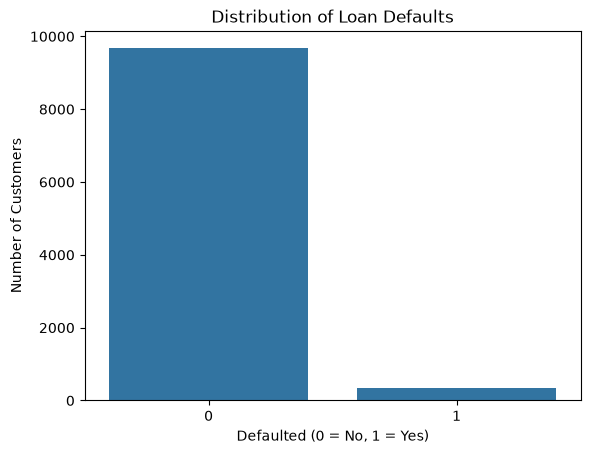

In [11]:
sns.countplot(data=df,x="Defaulted?")
plt.title("Distribution of Loan Defaults")
plt.xlabel("Defaulted (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

#### Visualizing Employment Status

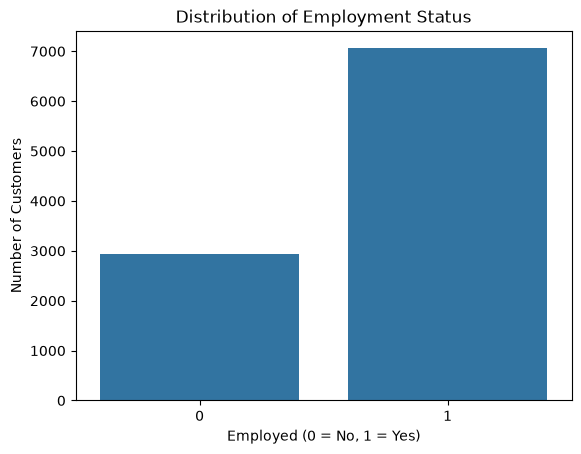

In [12]:
sns.countplot(data=df, x="Employed")
plt.title("Distribution of Employment Status")
plt.xlabel("Employed (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()


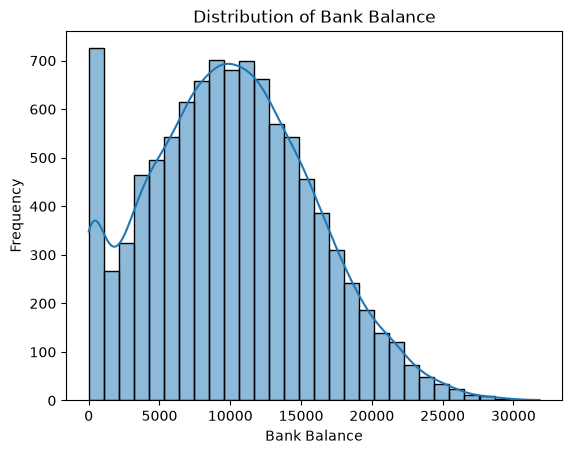

In [13]:
sns.histplot(data=df, x="Bank Balance", bins=30, kde=True)

plt.title("Distribution of Bank Balance")
plt.xlabel("Bank Balance")
plt.ylabel("Frequency")

plt.show()

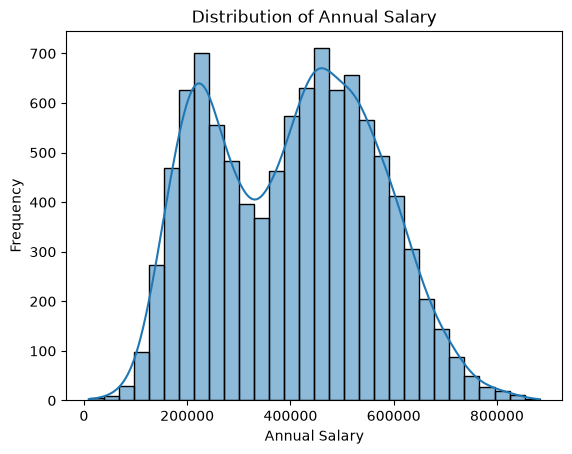

In [14]:
sns.histplot(data=df, x="Annual Salary", bins=30, kde=True)

plt.title("Distribution of Annual Salary")
plt.xlabel("Annual Salary")
plt.ylabel("Frequency")

plt.show()

#### Detecting outliers 

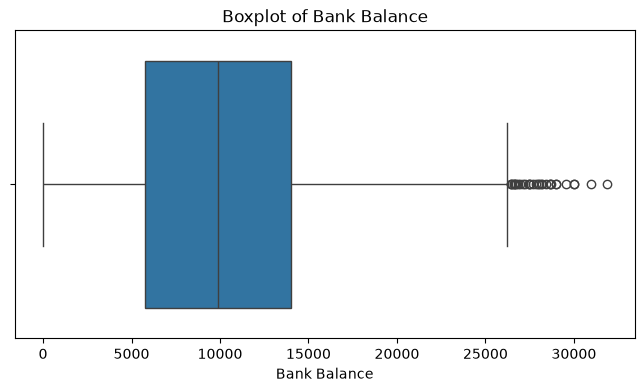

In [15]:
plt.figure(figsize=(8,4))
sns.boxplot(data=df,x="Bank Balance")
plt.title("Boxplot of Bank Balance")
plt.xlabel("Bank Balance")
plt.show()

In [16]:
Q1 = df["Bank Balance"].quantile(0.25)
Q3 = df["Bank Balance"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 5780.79
Q3: 13995.66
IQR: 8214.869999999999
Lower Bound: -6541.5149999999985
Upper Bound: 26317.964999999997


In [17]:
outliers = df[
    (df["Bank Balance"] < lower_bound) |
    (df["Bank Balance"] > upper_bound)
]

print("Number of potential outliers:", len(outliers))
print("Percentage of potential outliers:", len(outliers) / len(df) * 100)

Number of potential outliers: 31
Percentage of potential outliers: 0.31


In [18]:
Q1_salary = df["Annual Salary"].quantile(0.25)
Q3_salary = df["Annual Salary"].quantile(0.75)

IQR_salary = Q3_salary - Q1_salary

lower_bound_salary = Q1_salary - 1.5 * IQR_salary
upper_bound_salary = Q3_salary + 1.5 * IQR_salary

salary_outliers = df[
    (df["Annual Salary"] < lower_bound_salary) |
    (df["Annual Salary"] > upper_bound_salary)
]

print("Q1:", Q1_salary)
print("Q3:", Q3_salary)
print("IQR:", IQR_salary)
print("Lower Bound:", lower_bound_salary)
print("Upper Bound:", upper_bound_salary)
print("Number of potential outliers:", len(salary_outliers))
print("Percentage of potential outliers:", len(salary_outliers) / len(df) * 100)

Q1: 256085.52
Q3: 525692.76
IQR: 269607.24
Lower Bound: -148325.34
Upper Bound: 930103.62
Number of potential outliers: 0
Percentage of potential outliers: 0.0


In [19]:
default_rate = pd.crosstab(
    df["Employed"],
    df["Defaulted?"],
    normalize="index"
) * 100

default_rate

Defaulted?,0,1
Employed,,
0,95.686141,4.313859
1,97.080499,2.919501


In [20]:
print("Employment values:", sorted(df["Employed"].unique()))
print("Default values:", sorted(df["Defaulted?"].unique()))
print("Unique Index values:", df["Index"].nunique())

Employment values: [np.int64(0), np.int64(1)]
Default values: [np.int64(0), np.int64(1)]
Unique Index values: 10000


### Separating Features and Target Variable



In [21]:
X = df[["Employed", "Bank Balance", "Annual Salary"]]
y = df["Defaulted?"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (10000, 3)
Target shape: (10000,)


### Splitting the Dataset into Training and Testing Sets

In [22]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test=train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8000, 3)
X_test: (2000, 3)
y_train: (8000,)
y_test: (2000,)


In [23]:
print("Training target distribution (%):")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution (%):")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution (%):
Defaulted?
0    96.675
1     3.325
Name: proportion, dtype: float64

Testing target distribution (%):
Defaulted?
0    96.65
1     3.35
Name: proportion, dtype: float64


In [24]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (8000, 3)
Scaled testing shape: (2000, 3)


### Logistic Regression

###### model training

In [25]:
from sklearn.linear_model import LogisticRegression
logistic_model=LogisticRegression()
logistic_model.fit(X_train_scaled,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

###### the trained model receives the features of 2,000 customers it hasn't seen during training.

In [26]:
y_model=logistic_model.predict(X_test_scaled)

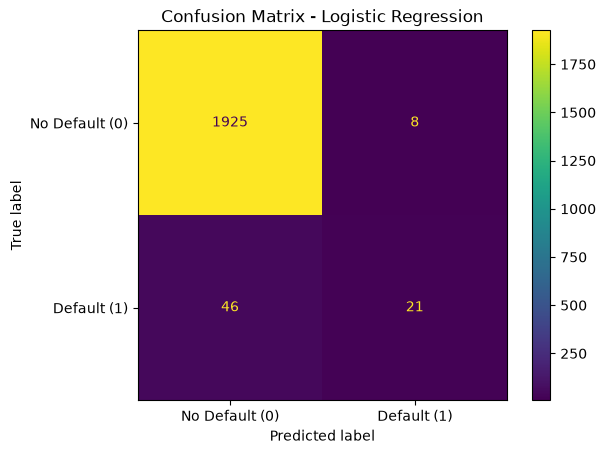

In [27]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm=confusion_matrix(y_test,y_model)
display=ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Default (0)", "Default (1)"] 
)
display.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

###### 1,925 customers: The model correctly identified customers who did not default.
###### 8 customers: The model incorrectly flagged customers as defaulters.
###### 46 customers: The model failed to identify customers who actually defaulted.
###### 21 customers: The model successfully identified actual defaulters.
###### The most important observation is that there were 67 actual defaulters in the test set, but the model identified only 21 of them.

In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_model))
print("Precision:", precision_score(y_test, y_model))
print("Recall:", recall_score(y_test, y_model))
print("F1-Score:", f1_score(y_test, y_model))

print("\nClassification Report:")
print(classification_report(y_test, y_model))

Accuracy: 0.973
Precision: 0.7241379310344828
Recall: 0.31343283582089554
F1-Score: 0.4375

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1933
           1       0.72      0.31      0.44        67

    accuracy                           0.97      2000
   macro avg       0.85      0.65      0.71      2000
weighted avg       0.97      0.97      0.97      2000



#### Logistic Regression with Class Weighting — Handling Class Imbalance
###### We use class weighting to handle the class imbalance in our dataset, where only 3.33% of customers defaulted. The `class_weight="balanced"` parameter gives more importance to the minority class during training, helping the model identify more potential defaulters.

In [29]:
logistic_balanced=LogisticRegression(class_weight="balanced")
logistic_balanced.fit(X_train_scaled,y_train)
y_pred_balanced=logistic_balanced.predict(X_test_scaled)

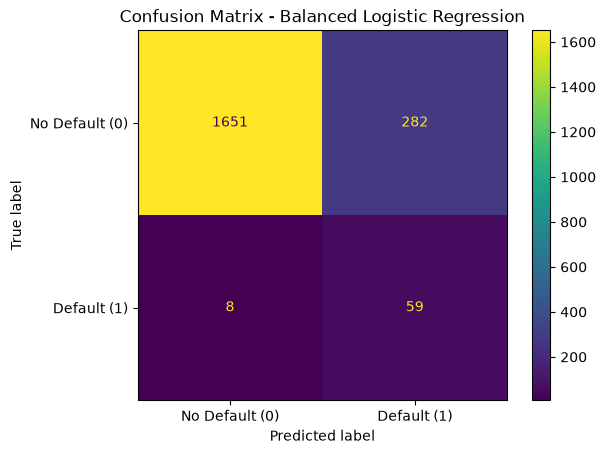

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_balanced = confusion_matrix(y_test, y_pred_balanced)

display_balanced = ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=["No Default (0)", "Default (1)"]
)

display_balanced.plot()
plt.title("Confusion Matrix - Balanced Logistic Regression")
plt.show()

#### Random Forest Classifier

In [31]:
from sklearn.ensemble import RandomForestClassifier
rf_model=RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)
rf_model.fit(X_train,y_train)
y_pred=rf_model.predict(X_test)

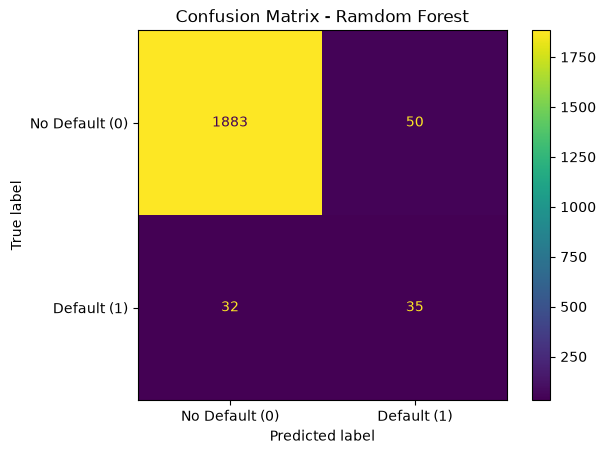

In [32]:
from sklearn.metrics import confusion_matrix
cm_rf=confusion_matrix(y_test,y_pred)
display=ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No Default (0)", "Default (1)"]
)
display.plot()
plt.title("Confusion Matrix - Ramdom Forest")
plt.show()

In [33]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.959
Precision: 0.4117647058823529
Recall: 0.5223880597014925
F1 Score: 0.4605263157894737


In [34]:
from sklearn.metrics import roc_auc_score
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)
print("Random Forest ROC-AUC:", roc_auc_rf)

Random Forest ROC-AUC: 0.8838901714912246


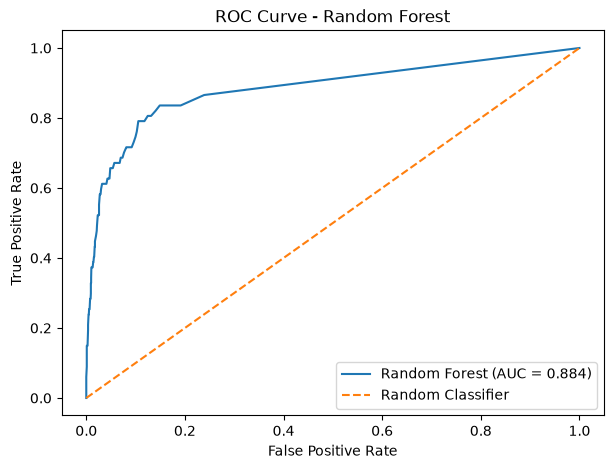

In [35]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc_rf:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")

plt.legend()
plt.show()

In [36]:
thresholds = [0.5, 0.4, 0.3, 0.2]

for threshold in thresholds:

    y_pred_threshold = (y_prob_rf >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Accuracy:", accuracy_score(y_test, y_pred_threshold))
    print("Precision:", precision_score(y_test, y_pred_threshold))
    print("Recall:", recall_score(y_test, y_pred_threshold))
    print("F1-score:", f1_score(y_test, y_pred_threshold))


Threshold: 0.5
Accuracy: 0.96
Precision: 0.42528735632183906
Recall: 0.5522388059701493
F1-score: 0.4805194805194805

Threshold: 0.4
Accuracy: 0.9535
Precision: 0.37962962962962965
Recall: 0.6119402985074627
F1-score: 0.4685714285714286

Threshold: 0.3
Accuracy: 0.9415
Precision: 0.3188405797101449
Recall: 0.6567164179104478
F1-score: 0.4292682926829268

Threshold: 0.2
Accuracy: 0.922
Precision: 0.2541436464088398
Recall: 0.6865671641791045
F1-score: 0.3709677419354839


#### Support Vector Machine

In [39]:
from sklearn.svm import SVC

svm_model=SVC(
    kernel="rbf",class_weight="balanced", random_state=42
)
svm_model.fit(X_train_scaled, y_train)
svm_pred=svm_model.predict(X_test_scaled)

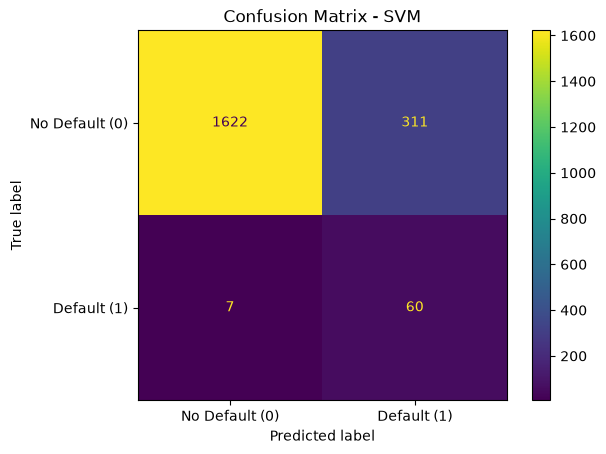

In [41]:
cm_svm=confusion_matrix(y_test,svm_pred)
display=ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=["No Default (0)", "Default (1)"]
)
display.plot()
plt.title("Confusion Matrix - SVM")
plt.show()

In [ ]:

print("Accuracy:", accuracy_score(y_test, svm_pred))
print("Precision:", precision_score(y_test, svm_pred))
print("Recall:", recall_score(y_test, svm_pred))
print("F1 Score:", f1_score(y_test, svm_pred))

Accuracy: 0.841
Precision: 0.16172506738544473
Recall: 0.8955223880597015
F1 Score: 0.273972602739726


In [45]:
from sklearn.metrics import roc_auc_score
y_score_svm = svm_model.decision_function(X_test_scaled)
roc_auc_svm = roc_auc_score(y_test, y_score_svm)
print("SVM ROC-AUC:", roc_auc_svm)

SVM ROC-AUC: 0.9152427206955394


#### XG Boost

In [46]:
from xgboost import XGBClassifier

In [53]:
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    scale_pos_weight=29,
    random_state=42,
    eval_metric="logloss"
)
xgb_model.fit(X_train, y_train)
xgb_pred=xgb_model.predict(X_test)


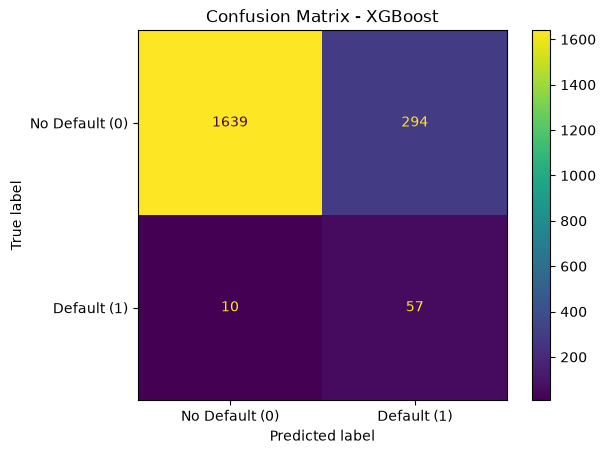

In [55]:
cn_svm=confusion_matrix(y_test,xgb_pred)
display=ConfusionMatrixDisplay(
    confusion_matrix=cn_svm,
    display_labels=["No Default (0)", "Default (1)"]
)
display.plot()
plt.title("Confusion Matrix - XGBoost")
plt.show()

In [57]:
print("Accuracy:", accuracy_score(y_test, xgb_pred))
print("Precision:", precision_score(y_test, xgb_pred))
print("Recall:", recall_score(y_test, xgb_pred))
print("F1 Score:", f1_score(y_test, xgb_pred))

Accuracy: 0.848
Precision: 0.1623931623931624
Recall: 0.8507462686567164
F1 Score: 0.2727272727272727


In [58]:
from sklearn.metrics import roc_auc_score
y_score_xgb = xgb_model.predict_proba(X_test)[:, 1]
roc_auc_xgb = roc_auc_score(y_test, y_score_xgb)
print("XGBoost ROC-AUC:", roc_auc_xgb)

XGBoost ROC-AUC: 0.9446456285566478


In [59]:
# Generate predictions
y_pred_logistic = logistic_model.predict(X_test_scaled)
y_pred_rf = rf_model.predict(X_test)
y_pred_svm = svm_model.predict(X_test_scaled)
y_pred_xgb = xgb_model.predict(X_test)

# Get continuous scores for ROC-AUC
y_score_logistic = logistic_model.predict_proba(X_test_scaled)[:, 1]
y_score_rf = rf_model.predict_proba(X_test)[:, 1]
y_score_svm = svm_model.decision_function(X_test_scaled)
y_score_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Store model predictions and scores
models = {
    "Logistic Regression": (y_pred_logistic, y_score_logistic),
    "Random Forest": (y_pred_rf, y_score_rf),
    "SVM": (y_pred_svm, y_score_svm),
    "XGBoost": (y_pred_xgb, y_score_xgb)
}

# Calculate evaluation metrics
results = []

for model_name, (predictions, scores) in models.items():

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, scores)
    })

comparison_df = pd.DataFrame(results)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.973,0.724138,0.313433,0.437500,0.948445
1,Random Forest,0.959,0.411765,0.522388,0.460526,0.883890
2,SVM,0.841,0.161725,0.895522,0.273973,0.915243
3,XGBoost,0.848,0.162393,0.850746,0.272727,0.944646


##### 9. Conclusion
- The dataset is highly imbalanced, with only 3.33% of customers defaulting. Therefore, accuracy alone is not a reliable measure of model performance.

- Logistic Regression achieved the highest accuracy (97.30%), precision (72.41%), and ROC-AUC (94.84%). However, its recall was only 31.34%, meaning it missed many actual defaulters.

- Random Forest achieved the highest F1-score (46.05%), providing the best balance between precision (41.18%) and recall (52.24%) among the four models.

- SVM achieved the highest recall (89.55%), identifying most actual defaulters, but its precision was low (16.17%), resulting in many false positives.

- XGBoost achieved a strong ROC-AUC of 94.46% and recall of 85.07%. However, its precision was only 16.24%, indicating that many predicted defaulters were actually non-defaulters.

- Overall, Random Forest provides the best precision-recall balance, while SVM is more suitable when identifying as many potential defaulters as possible is the priority.

- In a real-world deployment, the final model selection would depend on the cost of missing an actual defaulter versus incorrectly flagging a reliable customer.